# Tabular — Uplift / Efek Perlakuan (siapa yang perlu diberi promo?)
**Kapan dipakai:** ada perlakuan (promo, email, bantuan) yang diberikan secara acak ke
sebagian orang. Pertanyaannya bukan "siapa yang akan membeli", tetapi "siapa yang
**berubah** karena diberi perlakuan".

**Cara (T-learner):**
1. Satu model belajar dari grup yang diberi perlakuan.
2. Satu model lagi belajar dari grup kontrol (tidak diberi).
3. Uplift tiap orang = peluang jika diberi − peluang jika tidak diberi.

**Data demo:** Hillstrom email (perlakuan = dapat email, hasil = `visit`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular_extra/uplift"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/hillstrom.csv"

OUTCOME = "visit"                  # hasil yang ingin dinaikkan (1/0)
GROUP_COL = "segment"              # kolom yang mencatat perlakuan
CONTROL_VALUE = "No E-Mail"        # nilai di GROUP_COL untuk grup kontrol
NUM_COLS = ["recency", "history", "mens", "womens", "newbie"]
CAT_COLS = ["zip_code", "channel"]
EDA_COLS = ["channel", "zip_code", "newbie"]
TOP_SHARE = 0.3                    # beri promo ke 30% orang dengan uplift tertinggi
SEED = 42

## Baca data
Kolom `treatment`: 1 = diberi perlakuan, 0 = kontrol.

In [3]:
data = pd.read_csv(DATA_CSV)
data["treatment"] = (data[GROUP_COL] != CONTROL_VALUE).astype(int)
FEATURES = NUM_COLS + CAT_COLS
print(data.shape)
print(data.groupby("treatment")[OUTCOME].agg(["mean", "count"]))
data.head()

(64000, 14)
               mean  count
treatment                 
0          0.106167  21306
1          0.167049  42694


,id,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,treatment
0,0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0,1
1,1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,0
2,2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0,1
3,3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,1
4,4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,1


## EDA: efek rata-rata per kelompok
`uplift` = rata-rata hasil grup perlakuan − rata-rata hasil grup kontrol.

In [4]:
for col in EDA_COLS:
    mean_table = data.groupby([col, "treatment"])[OUTCOME].mean()
    mean_table = mean_table.unstack()
    mean_table["uplift"] = mean_table[1] - mean_table[0]
    print(mean_table.round(4), "\n")

treatment          0       1  uplift
channel                             
Multichannel  0.1285  0.1936  0.0650
Phone         0.0872  0.1471  0.0599
Web           0.1189  0.1796  0.0607 

treatment       0       1  uplift
zip_code                         
Rural      0.1536  0.2050  0.0515
Surburban  0.0990  0.1605  0.0615
Urban      0.0968  0.1601  0.0633 

treatment       0       1  uplift
newbie                           
0          0.1337  0.1927  0.0590
1          0.0788  0.1416  0.0628 



## Split train / validasi

In [5]:
train_part, val_part = train_test_split(data, test_size=0.3, stratify=data["treatment"],
                                        random_state=SEED)

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])
model = LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=100,
                       random_state=SEED, verbose=-1)
# model = LogisticRegression(max_iter=2000)
# model = RandomForestClassifier(n_estimators=300, min_samples_leaf=200, n_jobs=-1)

## T-learner
`clone` membuat salinan model yang belum dilatih, supaya dua model tidak saling menimpa.

In [7]:
def train_t_learner(table):
    treated = table[table["treatment"] == 1]
    control = table[table["treatment"] == 0]
    model_treated = make_pipeline(clone(preprocess), clone(model))
    model_control = make_pipeline(clone(preprocess), clone(model))
    model_treated.fit(treated[FEATURES], treated[OUTCOME])
    model_control.fit(control[FEATURES], control[OUTCOME])
    return model_treated, model_control


def predict_uplift(model_treated, model_control, table):
    proba_treated = model_treated.predict_proba(table[FEATURES])[:, 1]
    proba_control = model_control.predict_proba(table[FEATURES])[:, 1]
    return proba_treated - proba_control


model_treated, model_control = train_t_learner(train_part)
val_part = val_part.copy()
val_part["uplift"] = predict_uplift(model_treated, model_control, val_part)
val_part["uplift"].describe()

count    19200.000000
mean         0.063707
std          0.038089
min         -0.129530
25%          0.040154
50%          0.060283
75%          0.083524
max          0.295737
Name: uplift, dtype: float64

## Evaluasi: uplift nyata per desil
Orang validasi diurutkan menurut skor uplift, lalu dibagi 10 kelompok (desil 1 = skor
tertinggi). Model bagus → desil atas punya selisih (perlakuan − kontrol) paling besar.
Garis merah = efek rata-rata kalau semua orang diberi perlakuan.

treatment       0       1  real_uplift
decile                                
1          0.1566  0.2364       0.0798
2          0.1234  0.2141       0.0906
3          0.1204  0.1694       0.0490
4          0.0984  0.1582       0.0598
5          0.0982  0.1483       0.0501
6          0.1049  0.1301       0.0252
7          0.0984  0.1430       0.0445
8          0.0992  0.1416       0.0424
9          0.0872  0.1432       0.0560
10         0.1178  0.1653       0.0475


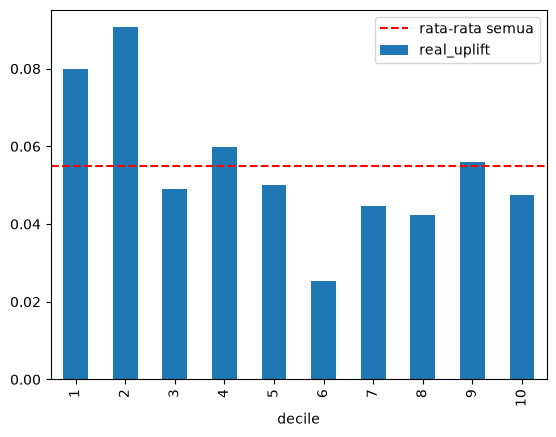

In [8]:
rank = val_part["uplift"].rank(method="first", ascending=False)
val_part["decile"] = pd.qcut(rank, 10, labels=False) + 1

decile_table = val_part.groupby(["decile", "treatment"])[OUTCOME].mean()
decile_table = decile_table.unstack()
decile_table["real_uplift"] = decile_table[1] - decile_table[0]
print(decile_table.round(4))

overall = val_part.groupby("treatment")[OUTCOME].mean()
decile_table["real_uplift"].plot.bar()
plt.axhline(overall[1] - overall[0], color="red", linestyle="--", label="rata-rata semua")
plt.legend()
plt.show()

Uplift nyata di 30% orang dengan skor tertinggi (desil 1–3).

In [9]:
top = val_part[val_part["decile"] <= 3]
top_mean = top.groupby("treatment")[OUTCOME].mean()
print("uplift nyata 30% teratas:", round(top_mean[1] - top_mean[0], 4))

uplift nyata 30% teratas: 0.073


## Latih ulang di semua data + daftar target
Hasil: skor uplift per orang. `target_promo` = 1 untuk `TOP_SHARE` orang dengan skor tertinggi.

In [10]:
model_treated, model_control = train_t_learner(data)
predictions = predict_uplift(model_treated, model_control, data)
cutoff = pd.Series(predictions).quantile(1 - TOP_SHARE)

submission = pd.DataFrame()
submission["id"] = data["id"]
submission["uplift"] = predictions
submission["target_promo"] = (predictions >= cutoff).astype(int)
submission.to_csv("submission.csv", index=False)
submission.head()

,id,uplift,target_promo
0,0,0.031098,0
1,1,0.002657,0
2,2,0.054698,0
3,3,0.010438,0
4,4,0.050648,0
